<a href="https://colab.research.google.com/github/LiliiaKuchvara/Python-DTA/blob/main/Pandas5_lesson_29_29_10_26_merge.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🐼📈 Pandas і графіки для аналітиків · Блокнот 5 з 7
## Об'єднання таблиць · 📈 Порівняння і зв'язки

У справжніх системах дані зберігаються в **кількох таблицях**:
- **замовлення**: хто, що і коли купив (лише коди клієнта й товару);
- **клієнти**: ім'я, місто, вік;
- **товари**: назва, категорія, ціна, собівартість.

Навіщо так? Щоб не повторювати ту саму інформацію тисячі разів. Але для аналізу таблиці треба **з'єднати**. В Excel для цього є ВПР (VLOOKUP), а в pandas — `merge()`.

### У цьому блокноті ви навчитеся
1. З'єднувати таблиці через `merge()` за спільним стовпцем (ключем).
2. Розуміти різницю між `inner` і `left`.
3. Перевіряти, що об'єднання пройшло правильно.
4. «Склеювати» таблиці однакової структури через `concat()`.
5. 📈 Показувати **два показники** на одному графіку.
6. 📈 Шукати **зв'язок між числами** на точковій діаграмі (scatter) і підписувати точки.
7. 📈 Дивитися на **розподіл** клієнтів за кількістю замовлень.

### Як працювати з блокнотом
- Запускайте клітинки **по черзі зверху вниз**: кнопка ▶ ліворуч або **`Shift + Enter`**.
- **Першою** запустіть клітинку «📦 Підготовка даних»: вона створить файли з даними.
- Змінюйте числа й умови в прикладах і дивіться, що вийде. Зламати нічого не можна.
- У практиці пишіть код у клітинках «Ваш код тут». Розв'язки всіх завдань зібрані в **останній клітинці** блокнота. Спершу спробуйте самостійно, а туди зазирайте, лише якщо справді застрягли.
- Розділи з позначкою **📈** — про графіки. Вони йдуть паралельно з pandas і поступово ускладнюються від блокнота до блокнота.

<details>
<summary><b>📚 Увесь курс</b></summary>

01. Знайомство з pandas · 📈 Перший графік<br>02. Вибір, фільтрація та сортування · 📈 Налаштовуємо вигляд графіка<br>03. Нові стовпці та очищення даних · 📈 Графіки для перевірки даних<br>04. Групування та зведені таблиці · 📈 Графіки з групувань<br>**05. Об'єднання таблиць · 📈 Порівняння і зв'язки** ← ви тут<br>06. Робота з датами · 📈 Графіки динаміки<br>07. Фінальний проєкт · 📈 Дашборд для керівника

</details>

## Крок 0. Готуємо дані

In [1]:
# @title 📦 Підготовка даних — просто запустіть цю клітинку (Shift + Enter)
# Ця клітинка створює навчальні файли з даними інтернет-магазину за 2025 рік.
# Розбиратися в її коді не потрібно.
# Якщо Colab перезапустився і файли зникли — просто запустіть її ще раз.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rng = np.random.default_rng(2025)

# ---------- Товари ----------
products = pd.DataFrame([
    ("P01", "Headphones",         "Electronics", 1500,  900),
    ("P02", "Power bank",         "Electronics",  900,  520),
    ("P03", "Smartwatch",    "Electronics", 4200, 2900),
    ("P04", "Bluetooth speaker", "Electronics", 2100, 1300),
    ("P05", "T-shirt",          "Clothing",         450,  180),
    ("P06", "Hoodie",              "Clothing",        1200,  550),
    ("P07", "Jeans",            "Clothing",        1600,  800),
    ("P08", "Sneakers",          "Clothing",        2800, 1600),
    ("P09", "Mug",             "Home",          180,   60),
    ("P10", "Blanket",              "Home",          850,  400),
    ("P11", "Desk lamp",   "Home",         1100,  600),
    ("P12", "Towel set",    "Home",          650,  300),
    ("P13", "Face cream",  "Beauty",        520,  210),
    ("P14", "Shampoo",           "Beauty",        260,  110),
    ("P15", "Perfume",           "Beauty",       2400, 1300),
    ("P16", "Yoga mat",  "Sports",        700,  320),
    ("P17", "Water bottle",   "Sports",        350,  140),
    ("P18", "Dumbbells 5 kg",      "Sports",        950,  550),
], columns=["product_id", "product", "category", "price", "cost"])

# ---------- Клієнти ----------
n_cust = 400
names = ["Olena", "Andrii", "Mariia", "Ihor", "Nataliia", "Dmytro", "Iryna", "Oleksandr",
         "Tetiana", "Serhii", "Yuliia", "Maksym", "Oksana", "Viktor", "Anna", "Bohdan",
         "Kateryna", "Taras", "Sofiia", "Roman"]
cities = ["Kyiv", "Lviv", "Odesa", "Kharkiv", "Dnipro"]
reg = pd.Timestamp("2022-01-01") + pd.to_timedelta(rng.integers(0, 3 * 365, n_cust), unit="D")
customers = pd.DataFrame({
    "customer_id": [f"C{i:04d}" for i in range(1, n_cust + 1)],
    "name": rng.choice(names, n_cust),
    "city": rng.choice(cities, n_cust, p=[0.35, 0.2, 0.15, 0.15, 0.15]),
    "age": np.clip(rng.normal(33, 9, n_cust).round(), 18, 65).astype(int),
    "registration_date": reg.strftime("%Y-%m-%d"),
})

# ---------- Замовлення ----------
n = 3000
days = pd.date_range("2025-01-01", "2025-12-31")
w = np.linspace(0.85, 1.15, len(days))          # магазин поступово росте
w[days.month.isin([6, 7, 8])] *= 0.8            # влітку спокійніше
w[days.month.isin([11, 12])] *= 1.5             # сезон розпродажів і свят
w[days.dayofweek >= 5] *= 1.3                   # у вихідні купують більше
w[days == pd.Timestamp("2025-11-28")] *= 6      # Чорна п'ятниця
order_date = pd.DatetimeIndex(np.sort(rng.choice(days.values, n, p=w / w.sum())))

cust_w = rng.gamma(1.0, 1, n_cust)
cust_idx = rng.choice(n_cust, n, p=cust_w / cust_w.sum())
prod_w = 1 / np.sqrt(products["price"].to_numpy())
prod_idx = rng.choice(len(products), n, p=prod_w / prod_w.sum())

quantity = rng.choice([1, 2, 3, 4], n, p=[0.72, 0.18, 0.07, 0.03])
payment = rng.choice(["Card", "Cash on delivery", "Google/Apple Pay"], n, p=[0.55, 0.27, 0.18])
channel = rng.choice(["Website", "App", "Instagram"], n, p=[0.5, 0.35, 0.15])

cod = payment == "Cash on delivery"
u = rng.random(n)
status = np.where(u < np.where(cod, 0.80, 0.91), "Delivered",
                  np.where(u < np.where(cod, 0.92, 0.96), "Cancelled", "Returned"))

city = customers["city"].to_numpy()[cust_idx]
deliv_days = np.where(city == "Kyiv", rng.integers(1, 3, n), rng.integers(1, 6, n))
delivery = order_date + pd.to_timedelta(deliv_days, unit="D")
delivery_str = np.where(status == "Cancelled", None, delivery.strftime("%Y-%m-%d"))

rating = np.where(deliv_days >= 4,
                  rng.choice(5, n, p=[0.08, 0.12, 0.22, 0.33, 0.25]) + 1,
                  rng.choice(5, n, p=[0.03, 0.05, 0.12, 0.35, 0.45]) + 1).astype(float)
returned = status == "Returned"
rating[returned] = rng.choice([1, 2, 3], returned.sum(), p=[0.5, 0.3, 0.2])
rating[(status == "Cancelled") | (rng.random(n) > 0.6)] = np.nan

orders = pd.DataFrame({
    "order_id": np.arange(100001, 100001 + n),
    "order_date": order_date.strftime("%Y-%m-%d"),
    "delivery_date": delivery_str,
    "customer_id": customers["customer_id"].to_numpy()[cust_idx],
    "product_id": products["product_id"].to_numpy()[prod_idx],
    "quantity": quantity,
    "payment": payment,
    "channel": channel,
    "status": status,
    "rating": rating,
})

# ---------- Одна велика таблиця продажів ----------
sales = (orders.merge(customers[["customer_id", "city"]], on="customer_id", how="left")
               .merge(products[["product_id", "product", "category", "price"]], on="product_id", how="left"))
sales = sales[["order_id", "order_date", "delivery_date", "customer_id", "city", "category",
               "product", "price", "quantity", "payment", "channel", "status", "rating"]]
sales = sales.sort_values("order_id").reset_index(drop=True)

# ---------- Квартальні вивантаження ----------
quarter = pd.to_datetime(sales["order_date"]).dt.quarter
for q in range(1, 5):
    sales[quarter == q].to_csv(f"sales_2025_Q{q}.csv", index=False)

# ---------- «Брудне» вивантаження продажів ----------
raw = sales.copy()
raw["price"] = raw["price"].astype(str) + " UAH"
raw["order_date"] = pd.to_datetime(raw["order_date"]).dt.strftime("%d.%m.%Y")
raw["delivery_date"] = pd.to_datetime(raw["delivery_date"]).dt.strftime("%d.%m.%Y")
messy = {"Kyiv": ["kyiv", "KYIV", " Kyiv", "Kiev"], "Lviv": ["lviv", "Lviv ", " LVIV"],
         "Odesa": ["odesa", "Odesa "], "Kharkiv": ["kharkiv", "KHARKIV "], "Dnipro": ["dnipro", " Dnipro"]}
city_col = raw["city"].to_numpy(dtype=object)
for i in rng.choice(n, 300, replace=False):
    city_col[i] = rng.choice(messy[city_col[i]])
city_col[rng.choice(n, 15, replace=False)] = None
raw["city"] = city_col
qty_col = raw["quantity"].to_numpy(dtype=float)
qty_col[rng.choice(n, 40, replace=False)] = np.nan
raw["quantity"] = qty_col
pay_col = raw["payment"].to_numpy(dtype=object)
pay_col[rng.choice(n, 60, replace=False)] = None
raw["payment"] = pay_col
raw = pd.concat([raw, raw.iloc[rng.choice(n, 25, replace=False)]])
raw = raw.sort_values("order_id", kind="stable").reset_index(drop=True)
raw.columns = ["Order ID", "Order Date", "Delivery Date", "Customer ID", "City", "Category",
               "Product", "Price", "Qty", "Payment", "Channel", "Status", "Rating"]

# ---------- «Брудний» список клієнтів ----------
craw = customers.copy()
name_col = craw["name"].to_numpy(dtype=object)
for i in rng.choice(n_cust, 40, replace=False):
    name_col[i] = rng.choice([name_col[i].lower(), name_col[i].upper(), " " + name_col[i] + " "])
craw["name"] = name_col
cc = craw["city"].to_numpy(dtype=object)
for i in rng.choice(n_cust, 50, replace=False):
    cc[i] = rng.choice([cc[i].lower(), cc[i].upper(), cc[i] + " "])
craw["city"] = cc
age_col = craw["age"].to_numpy(dtype=float)
age_col[rng.choice(n_cust, 12, replace=False)] = np.nan
craw["age"] = age_col
craw["registration_date"] = pd.to_datetime(craw["registration_date"]).dt.strftime("%d/%m/%Y")
craw = pd.concat([craw, craw.iloc[rng.choice(n_cust, 8, replace=False)]])
craw = craw.sort_values("customer_id", kind="stable").reset_index(drop=True)

# ---------- Зберігаємо файли ----------
sales.to_csv("sales.csv", index=False)
orders.to_csv("orders.csv", index=False)
customers.to_csv("customers.csv", index=False)
products.to_csv("products.csv", index=False)
raw.to_csv("sales_raw.csv", index=False)
craw.to_csv("customers_raw.csv", index=False)

# ---------- Налаштування вигляду таблиць і стиль графіків (з блокнота 2) ----------
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}".replace(",", " "))
plt.rcParams.update({
    "figure.figsize": (8, 4),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.alpha": 0.3,
    "lines.linewidth": 2,
    "legend.frameon": False,
    "axes.prop_cycle": plt.cycler(color=["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
                                         "#e87ba4", "#008300", "#6250d6", "#e34948"]),
})

del (rng, names, cities, reg, n, n_cust, days, w, order_date, cust_w, cust_idx, prod_w, prod_idx,
     quantity, payment, channel, cod, u, status, city, deliv_days, delivery, delivery_str, rating,
     returned, quarter, q, raw, messy, city_col, qty_col, pay_col, craw, name_col, cc, age_col, i,
     sales, orders, customers, products)

print("✅ Done! Data files created:")
print("   sales.csv, orders.csv, customers.csv, products.csv,")
print("   sales_raw.csv, customers_raw.csv, sales_2025_Q1…Q4.csv")

✅ Done! Data files created:
   sales.csv, orders.csv, customers.csv, products.csv,
   sales_raw.csv, customers_raw.csv, sales_2025_Q1…Q4.csv


In [2]:
import pandas as pd
import matplotlib.pyplot as plt

---
## Крок 1. Розбираємось на маленькому прикладі

Створимо дві крихітні таблиці, щоб усе було видно з першого погляду:

In [3]:
orders_small = pd.DataFrame({
    "order_id":    [1, 2, 3, 4],
    "customer_id": ["C1", "C2", "C1", "C9"],   # клієнта C9 немає в довіднику!
    "amount":      [900, 450, 1500, 700],
})

customers_small = pd.DataFrame({
    "customer_id": ["C1", "C2", "C3"],         # C3 нічого не замовляв
    "name":        ["Olena", "Andrii", "Mariia"],
    "city":        ["Kyiv", "Lviv", "Odesa"],
})

print("Orders:")
display(orders_small)
print("Customers:")
display(customers_small)

Orders:


,order_id,customer_id,amount
0,1,C1,900
1,2,C2,450
2,3,C1,1500
3,4,C9,700


Customers:


,customer_id,name,city
0,C1,Olena,Kyiv
1,C2,Andrii,Lviv
2,C3,Mariia,Odesa


💡 `display()` показує таблицю так само гарно, як остання команда в клітинці. Він зручний, коли потрібно показати кілька таблиць в одній клітинці.

Спільний стовпець в обох таблицях — **`customer_id`**. Він називається **ключем**: саме за ним pandas шукатиме відповідності.

### 1.1 `how="inner"`: тільки ті, хто є в обох таблицях

In [4]:
pd.merge(orders_small, customers_small, on="customer_id", how="inner")

,order_id,customer_id,amount,name,city
0,1,C1,900,Olena,Kyiv
1,2,C2,450,Andrii,Lviv
2,3,C1,1500,Olena,Kyiv


Замовлення №4 (клієнт C9) **зникло**, бо C9 немає в довіднику клієнтів. Марія (C3) теж не з'явилася: в неї немає замовлень.

### 1.2 `how="left"`: усі рядки з лівої (першої) таблиці

In [6]:
pd.merge(orders_small, customers_small, on="customer_id", how="left")

,order_id,customer_id,amount,name,city
0,1,C1,900,Olena,Kyiv
1,2,C2,450,Andrii,Lviv
2,3,C1,1500,Olena,Kyiv
3,4,C9,700,NaN,NaN


Тепер **усі 4 замовлення** на місці. Для C9 ім'я та місто порожні (`NaN`), бо їх ніде не знайшли. Так працює ВПР в Excel, коли повертає `#Н/Д`.

### Яке об'єднання обрати?

| `how=` | Що лишається | Коли використовувати |
|---|---|---|
| `"left"` | **усі** рядки першої таблиці + знайдене з другої | **найчастіше**: «додай до замовлень інформацію про клієнтів» |
| `"inner"` | тільки рядки, що є **в обох** таблицях | коли потрібні лише повні збіги |
| `"right"` | усі рядки другої таблиці | рідко: простіше поміняти таблиці місцями і взяти `left` |
| `"outer"` | усі рядки з **обох** таблиць | щоб побачити все, включно з тим, що не збіглося |

💡 Якщо `how` не вказати, pandas використає `"inner"`. Тому краще **завжди писати `how` явно**, щоб випадково не втратити рядки.

---
## Крок 2. Об'єднуємо справжні дані

Завантажимо три таблиці магазину:

In [7]:
orders = pd.read_csv("orders.csv")
customers = pd.read_csv("customers.csv")
products = pd.read_csv("products.csv")

print("orders:   ", orders.shape)
print("customers:", customers.shape)
print("products: ", products.shape)

orders:    (3000, 10)
customers: (400, 5)
products:  (18, 5)


In [8]:
orders.head(3)

,order_id,order_date,delivery_date,customer_id,product_id,quantity,payment,channel,status,rating
0,100001,2025-01-01,NaN,C0230,P18,4,Card,Website,Cancelled,NaN
1,100002,2025-01-01,2025-01-02,C0074,P03,3,Google/Apple Pay,Website,Delivered,5.00
2,100003,2025-01-01,2025-01-05,C0216,P03,1,Google/Apple Pay,Website,Delivered,NaN


In [9]:
products.head(3)

,product_id,product,category,price,cost
0,P01,Headphones,Electronics,1500,900
1,P02,Power bank,Electronics,900,520
2,P03,Smartwatch,Electronics,4200,2900


У замовленнях є лише `product_id`. Щоб дізнатися назву, категорію, ціну й собівартість, додамо інформацію з таблиці товарів. Ключ — **`product_id`**.

Ще один спосіб запису: `таблиця1.merge(таблиця2, ...)`. Він робить те саме, що `pd.merge(таблиця1, таблиця2, ...)`.

In [11]:
data = orders.merge(products, on="product_id", how="left")

data.head(3)

,order_id,order_date,delivery_date,customer_id,product_id,quantity,payment,channel,status,rating,product,category,price,cost
0,100001,2025-01-01,NaN,C0230,P18,4,Card,Website,Cancelled,NaN,Dumbbells 5 kg,Sports,950,550
1,100002,2025-01-01,2025-01-02,C0074,P03,3,Google/Apple Pay,Website,Delivered,5.00,Smartwatch,Electronics,4200,2900
2,100003,2025-01-01,2025-01-05,C0216,P03,1,Google/Apple Pay,Website,Delivered,NaN,Smartwatch,Electronics,4200,2900


### ✅ Перевірка після кожного об'єднання
Об'єднання — місце, де найчастіше трапляються тихі помилки. Перевіряйте дві речі:
1. **Кількість рядків не змінилася** (для `left` з довідником вона має лишитися такою самою).
2. **Немає нових пропусків** там, де їх не повинно бути (а якщо є, значить, якийсь ключ не знайшовся).

In [12]:
print("Rows before:", len(orders), "| after:", len(data))
print("Orders without a matching product:", data["product"].isna().sum())

Rows before: 3000 | after: 3000
Orders without a matching product: 0


Тепер додамо клієнтів. Об'єднання можна писати **ланцюжком**:

In [13]:
data = (
    orders
    .merge(products, on="product_id", how="left")
    .merge(customers, on="customer_id", how="left")
)

print("Rows:", len(data))
print("Orders without a matching customer:", data["name"].isna().sum())
data.head(3)

Rows: 3000
Orders without a matching customer: 0


,order_id,order_date,delivery_date,customer_id,product_id,quantity,payment,channel,status,rating,product,category,price,cost,name,city,age,registration_date
0,100001,2025-01-01,NaN,C0230,P18,4,Card,Website,Cancelled,NaN,Dumbbells 5 kg,Sports,950,550,Sofiia,Kyiv,29,2023-01-28
1,100002,2025-01-01,2025-01-02,C0074,P03,3,Google/Apple Pay,Website,Delivered,5.00,Smartwatch,Electronics,4200,2900,Oksana,Odesa,33,2023-09-21
2,100003,2025-01-01,2025-01-05,C0216,P03,1,Google/Apple Pay,Website,Delivered,NaN,Smartwatch,Electronics,4200,2900,Kateryna,Odesa,43,2023-12-09


### 2.1 Навіщо це все: прибуток!
Тепер в одній таблиці є і ціна, і **собівартість**, тож можна порахувати не лише виручку, а й **прибуток**.

In [14]:
data["revenue"] = data["price"] * data["quantity"]
data["profit"] = (data["price"] - data["cost"]) * data["quantity"]

delivered = data[data["status"] == "Delivered"]

category_profit = delivered.groupby("category").agg(
    revenue=("revenue", "sum"),
    profit=("profit", "sum"),
)
category_profit["margin_%"] = (category_profit["profit"] / category_profit["revenue"] * 100).round(1)

category_profit.sort_values("profit", ascending=False)

,revenue,profit,margin_%
category,,,
Electronics,1143600,412680,36.10
Clothing,812700,409570,50.40
Home,594480,312020,52.50
Beauty,544540,277870,51.00
Sports,429500,214560,50.00


**💡 Інсайт:** найбільша виручка не завжди означає найбільший прибуток. Категорія `Electronics` лідирує за виручкою, але її **маржа** (частка прибутку у виручці) найнижча, бо товари дорогі в закупівлі. Категорія `Clothing` продається на третину менше, а прибутку приносить майже стільки ж!

### 📈 Виручка і прибуток поруч
Таблицю з двома стовпцями можна намалювати одразу: кожен стовпець отримає свій колір. Назви стовпців стануть підписами в легенді, тому дамо їм зрозумілі назви з великої літери.

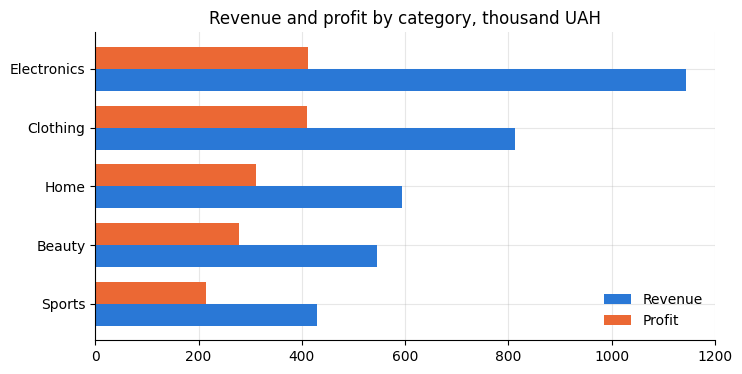

In [15]:
chart_data = (category_profit[["revenue", "profit"]] / 1000).sort_values("revenue")
chart_data.columns = ["Revenue", "Profit"]

chart_data.plot(kind="barh", width=0.75)
plt.title("Revenue and profit by category, thousand UAH")
plt.ylabel("")
plt.legend(loc="lower right")
plt.show()

На графіку видно те саме, що ми помітили в таблиці: в `Electronics` найдовший стовпчик виручки, а от стовпчик прибутку майже такий самий, як у `Clothing`.

---
## 📈 Точкова діаграма: чи є зв'язок між двома числами?

**Точкова діаграма** (scatter) показує кожен об'єкт точкою: положення по горизонталі — одне число, по вертикалі — інше. Так шукають зв'язок: «чим більше X, тим більше (або менше) Y?»

Питання: **чи правда, що дорожчі товари менш маржинальні?** Порахуємо для кожного товару ціну, маржу і кількість проданих одиниць.

In [16]:
product_stats = delivered.groupby("product").agg(
    price=("price", "first"),            # ціна однакова в усіх рядках товару, беремо першу
    revenue=("revenue", "sum"),
    profit=("profit", "sum"),
    units=("quantity", "sum"),
)
product_stats["margin_%"] = (product_stats["profit"] / product_stats["revenue"] * 100).round(1)

product_stats.sort_values("price").head()

,price,revenue,profit,units,margin_%
product,,,,,
Mug,180,80280,53520,446,66.70
Shampoo,260,92300,53250,355,57.70
Water bottle,350,91700,55020,262,60.00
T-shirt,450,110700,66420,246,60.00
Face cream,520,125840,75020,242,59.60


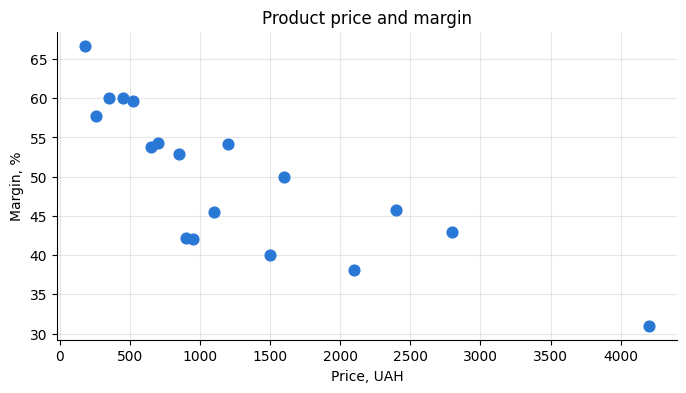

In [17]:
product_stats.plot(kind="scatter", x="price", y="margin_%", s=60)    # s — розмір точок
plt.title("Product price and margin")
plt.xlabel("Price, UAH")
plt.ylabel("Margin, %")
plt.show()

Точки йдуть «згори вниз»: що дорожчий товар, то нижча маржа. Але незрозуміло, яка точка — який товар.

### 📈 Підписуємо точки
Напис ставить `plt.text(x, y, "text")`. Щоб підписати кілька точок, пройдемося по таблиці циклом `for`.

Підписувати **всі** 18 точок не варто: дешеві товари стоять тісно, і написи заважають один одному. Підпишемо ті, про які говоримо: дорогі товари (від 1500 грн) і найдешевший.

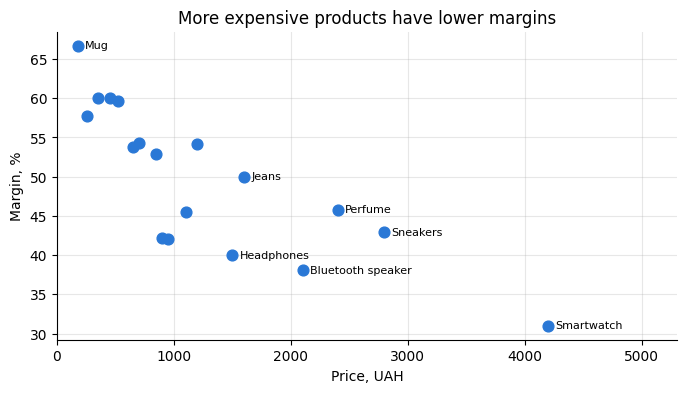

In [18]:
product_stats.plot(kind="scatter", x="price", y="margin_%", s=60)

for name, row in product_stats.iterrows():              # name — назва товару, row — його рядок
    if row["price"] >= 1500 or row["price"] == product_stats["price"].min():
        plt.text(row["price"] + 60, row["margin_%"], name, fontsize=8, va="center")

plt.xlim(0, 5300)                                         # місце праворуч для підпису найдорожчого товару
plt.title("More expensive products have lower margins")
plt.xlabel("Price, UAH")
plt.ylabel("Margin, %")
plt.show()

💡 `iterrows()` по черзі дає назву рядка (`name`) і сам рядок (`row`). Підпис ставимо трохи правіше від точки (`+ 60` грн), щоб текст не накривав її, а `va="center"` вирівнює текст по висоті точки.

### 📈 Третій показник: розмір точки
Розмір точки може показувати ще одне число, наприклад кількість проданих одиниць. Такий графік називають **бульбашковим**:

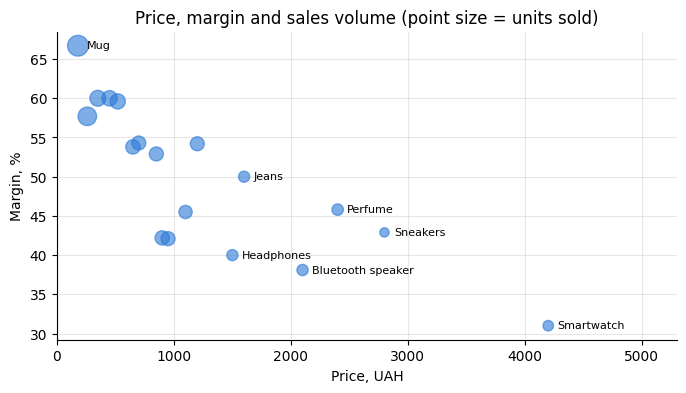

In [19]:
product_stats.plot(
    kind="scatter", x="price", y="margin_%",
    s=product_stats["units"] / 2,            # що більше продано, то більша точка
    alpha=0.6,                               # напівпрозорі точки: видно, якщо перекриваються
)
for name, row in product_stats.iterrows():
    if row["price"] >= 1500 or row["price"] == product_stats["price"].min():
        plt.text(row["price"] + 80, row["margin_%"], name, fontsize=8, va="center")

plt.xlim(0, 5300)
plt.title("Price, margin and sales volume (point size = units sold)")
plt.xlabel("Price, UAH")
plt.ylabel("Margin, %")
plt.show()

**Що видно:** найбільші «бульбашки» (найбільше продажів) — дешеві товари з високою маржею. Дорогі товари продаються рідше і мають нижчу маржу, але приносять багато виручки за кожен продаж.

---
## Крок 3. Коли ключі називаються по-різному: `left_on` / `right_on`

Буває, що в одній таблиці ключ називається `product_id`, а в іншій, наприклад, `sku`. Тоді вказуємо обидві назви:

In [20]:
suppliers = pd.DataFrame({
    "sku":      ["P01", "P02", "P03", "P04"],
    "supplier": ["TechnoOpt", "TechnoOpt", "SmartWear", "TechnoOpt"],
})

products.merge(suppliers, left_on="product_id", right_on="sku", how="left").head(6)

,product_id,product,category,price,cost,sku,supplier
0,P01,Headphones,Electronics,1500,900,P01,TechnoOpt
1,P02,Power bank,Electronics,900,520,P02,TechnoOpt
2,P03,Smartwatch,Electronics,4200,2900,P03,SmartWear
3,P04,Bluetooth speaker,Electronics,2100,1300,P04,TechnoOpt
4,P05,T-shirt,Clothing,450,180,NaN,NaN
5,P06,Hoodie,Clothing,1200,550,NaN,NaN


Для товарів, яких немає в таблиці постачальників, отримали `NaN`. Зайвий стовпець `sku` можна прибрати через `.drop(columns=["sku"])`.

---
## Крок 4. Хто нічого не купив? Шукаємо «неактивних» клієнтів

Класичне завдання для маркетингу: знайти клієнтів, які **жодного разу** не купували у 2025 році, щоб надіслати їм промокод.

**Спосіб 1: `isin`.** Беремо клієнтів, чиїх кодів **немає** серед кодів у замовленнях:

In [21]:
inactive = customers[~customers["customer_id"].isin(orders["customer_id"])]

print("Inactive customers:", len(inactive))
inactive.head()

Inactive customers: 43


,customer_id,name,city,age,registration_date
16,C0017,Dmytro,Lviv,46,2024-11-23
17,C0018,Sofiia,Lviv,44,2024-01-11
27,C0028,Bohdan,Lviv,39,2022-06-18
69,C0070,Ihor,Odesa,35,2024-05-31
76,C0077,Kateryna,Lviv,39,2024-11-10


**Спосіб 2: `merge` + `left`.** Рахуємо замовлення кожного клієнта і приєднуємо до **повного** списку клієнтів. Ті, кого не знайшли, отримають `NaN`, який ми замінимо на 0:

In [22]:
orders_per_customer = orders.groupby("customer_id")["order_id"].count().reset_index(name="orders")

customer_activity = customers.merge(orders_per_customer, on="customer_id", how="left")
customer_activity["orders"] = customer_activity["orders"].fillna(0).astype(int)

customer_activity.sort_values("orders", ascending=False).head()

,customer_id,name,city,age,registration_date,orders
190,C0191,Oleksandr,Kyiv,42,2022-01-13,45
251,C0252,Olena,Lviv,28,2023-02-09,42
335,C0336,Dmytro,Kharkiv,33,2024-10-17,34
274,C0275,Ihor,Kharkiv,24,2022-08-13,33
25,C0026,Mariia,Lviv,34,2022-07-02,32


Другий спосіб довший, зате дає повну картину: скільки замовлень у **кожного** клієнта, включно з нулями.

💡 `reset_index(name="orders")` перетворює результат групування на таблицю і одразу дає стовпцю з підрахунком зрозумілу назву.

In [23]:
print("Customers with 0 orders:", (customer_activity["orders"] == 0).sum())
print("Customers with 1 order:", (customer_activity["orders"] == 1).sum())
print("Customers with 5+ orders:", (customer_activity["orders"] >= 5).sum())

Customers with 0 orders: 43
Customers with 1 order: 48
Customers with 5+ orders: 210


### 📈 Розподіл клієнтів за кількістю замовлень

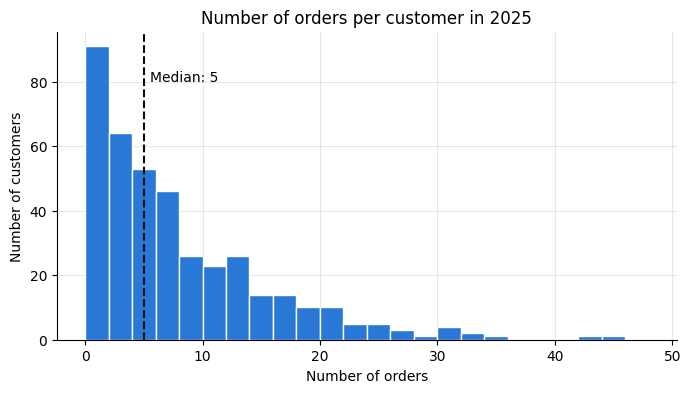

In [24]:
median_orders = customer_activity["orders"].median()

customer_activity["orders"].plot(kind="hist", bins=range(0, 50, 2), edgecolor="white")
plt.axvline(median_orders, color="#0b0b0b", linestyle="--", linewidth=1.5)
plt.text(median_orders + 0.5, 80, f"Median: {median_orders:.0f}")
plt.title("Number of orders per customer in 2025")
plt.xlabel("Number of orders")
plt.ylabel("Number of customers")
plt.show()

Більшість клієнтів зробили до 10 замовлень, але є невелика група «суперпокупців» з 30–45 замовленнями: довгий «хвіст» праворуч. Для маркетингу це дві різні аудиторії.

💡 `edgecolor="white"` малює білі проміжки між стовпчиками гістограми, щоб їх було легше розрізнити.

---
## Крок 5. ⚠️ Пастка: дублікати в довіднику

Якщо в таблиці-довіднику **ключ повторюється**, після `merge` рядки **розмножуться**, і всі суми стануть неправильними. Подивіться:

In [25]:
products_bad = pd.concat([products, products.head(1)])     # товар P01 випадково записали двічі

data_bad = orders.merge(products_bad, on="product_id", how="left")
print("Rows before:", len(orders), "| after:", len(data_bad), "← orders with P01 got duplicated!")

Rows before: 3000 | after: 3109 ← orders with P01 got duplicated!


**Як захиститися:**
1. Перед об'єднанням перевірте, що ключі в довіднику унікальні: `products["product_id"].duplicated().sum()` має дорівнювати 0.
2. Або додайте параметр `validate="many_to_one"` (багато замовлень → один товар). Якщо в довіднику дублікат, pandas одразу видасть помилку замість тихого задвоєння. Наприклад: `orders.merge(products, on="product_id", how="left", validate="many_to_one")`.

---
## Крок 6. Склеювання таблиць: `concat()`

`merge` з'єднує таблиці **«вбік»** (додає стовпці). А `concat` складає таблиці з **однаковими стовпцями** **«одна під одною»** (додає рядки).

Типова ситуація: щокварталу хтось вивантажує окремий файл, а вам потрібен рік. У нас є чотири файли `sales_2025_Q1.csv` … `sales_2025_Q4.csv`.

In [26]:
q1 = pd.read_csv("sales_2025_Q1.csv")
q2 = pd.read_csv("sales_2025_Q2.csv")

print("Q1:", q1.shape, "| Q2:", q2.shape)

half_year = pd.concat([q1, q2], ignore_index=True)    # ignore_index — пронумерувати рядки заново
print("First half of the year:", half_year.shape)

Q1: (551, 13) | Q2: (648, 13)
First half of the year: (1199, 13)


Коли файлів багато, їх зручно читати **циклом**. Заодно додамо стовпець з назвою кварталу, щоб пам'ятати, звідки рядок:

In [27]:
parts = []
for quarter in ["Q1", "Q2", "Q3", "Q4"]:
    part = pd.read_csv(f"sales_2025_{quarter}.csv")
    part["quarter"] = quarter
    parts.append(part)

year = pd.concat(parts, ignore_index=True)

print("Full year:", year.shape)
year["quarter"].value_counts().sort_index()

Full year: (3000, 14)


,count
quarter,
Q1,551
Q2,648
Q3,671
Q4,1130


---
# ✍️ Практика

Таблиці `orders`, `customers`, `products` вже завантажені вище.

**Завдання 1.** Об'єднайте `orders` і `customers` (ключ `customer_id`, `how="left"`). Перевірте, що кількість рядків не змінилася. Скільки замовлень зробили клієнти з кожного міста?

In [30]:
marge = orders.merge(customers, on="customer_id", how="left")
print("Rows before:", len(orders), "| after:", len(marge))

display(marge["city"].value_counts())


Rows before: 3000 | after: 3000


,count
city,
Kyiv,957
Lviv,678
Kharkiv,493
Dnipro,442
Odesa,430


**Завдання 2.** Додайте до `orders` інформацію про товари. Порахуйте **прибуток** кожного рядка: `(price - cost) * quantity`. Які 5 товарів принесли найбільший прибуток (тільки доставлені замовлення)?

In [34]:
op = orders.merge(products, on="product_id", how="left")
op["profit"] = (op["price"] - op["cost"]) * op["quantity"]

op_delivered = op[op["status"] == "Delivered"]
display(op_delivered.groupby("product")["profit"].sum().sort_values(ascending=False).head(5))



,profit
product,
Perfume,149600
Smartwatch,149500
Hoodie,131950
Sneakers,108000
Bluetooth speaker,105600


**Завдання 3.** Об'єднайте всі три таблиці. Який **середній вік** покупців у кожній категорії товарів?

In [35]:
full = (
    orders
    .merge(products, on="product_id", how="left")
    .merge(customers, on="customer_id", how="left")
)
display(full.groupby("category")["age"].mean().round(1).sort_values())

,age
category,
Home,32.30
Sports,32.30
Beauty,32.70
Electronics,33.10
Clothing,33.40


**Завдання 4.** У якому місті **найбільша частка** неактивних клієнтів (тих, хто нічого не купив)?

In [36]:
cust = customers.copy()
cust["is_inactive"] = ~cust["customer_id"].isin(orders["customer_id"])

display((cust.groupby("city")["is_inactive"].mean() * 100).round(1).sort_values(ascending=False))

,is_inactive
city,
Kharkiv,21.20
Lviv,14.60
Odesa,12.10
Kyiv,5.30
Dnipro,3.60


**Завдання 5 ⭐.** Склейте чотири квартальні файли в одну таблицю і порахуйте суму замовлень (`price * quantity`) по кварталах. Побудуйте стовпчиковий графік (`kind="bar"`).

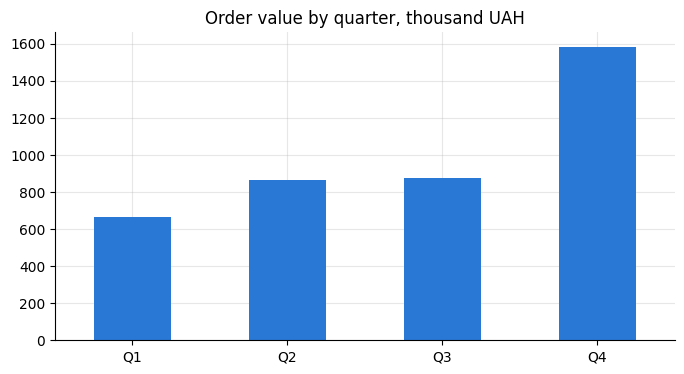

,revenue
quarter,
Q1,664.39
Q2,862.98
Q3,875.84
Q4,1 583.41


In [37]:
parts = []
for quarter in ["Q1", "Q2", "Q3", "Q4"]:
    part = pd.read_csv(f"sales_2025_{quarter}.csv")
    part["quarter"] = quarter
    parts.append(part)
year = pd.concat(parts, ignore_index=True)

year["revenue"] = year["price"] * year["quantity"]
by_quarter = year.groupby("quarter")["revenue"].sum() / 1000

by_quarter.plot(kind="bar", rot=0)       # rot=0 — підписи без нахилу
plt.title("Order value by quarter, thousand UAH")
plt.xlabel("")
plt.show()

display(by_quarter)

**Завдання 6 📈.** Чи витрачають старші клієнти більше? Для кожного клієнта порахуйте загальну суму **доставлених** замовлень, додайте його вік і побудуйте точкову діаграму «вік → сума покупок».

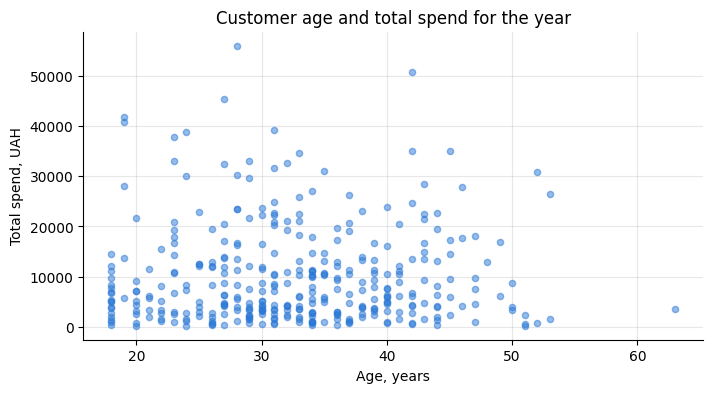

In [38]:
op = orders.merge(products, on="product_id", how="left")
op["revenue"] = op["price"] * op["quantity"]
spend = op[op["status"] == "Delivered"].groupby("customer_id")["revenue"].sum().reset_index()
spend = spend.merge(customers, on="customer_id", how="left")

spend.plot(kind="scatter", x="age", y="revenue", alpha=0.5)
plt.title("Customer age and total spend for the year")
plt.xlabel("Age, years")
plt.ylabel("Total spend, UAH")
plt.show()

**Завдання 7 📈⭐.** Побудуйте горизонтальний графік **частки неактивних клієнтів** по містах (з завдання 4), де місто з найбільшою часткою виділено червоним (`"#e34948"`), а решта сірі. Додайте підписи значень у відсотках.

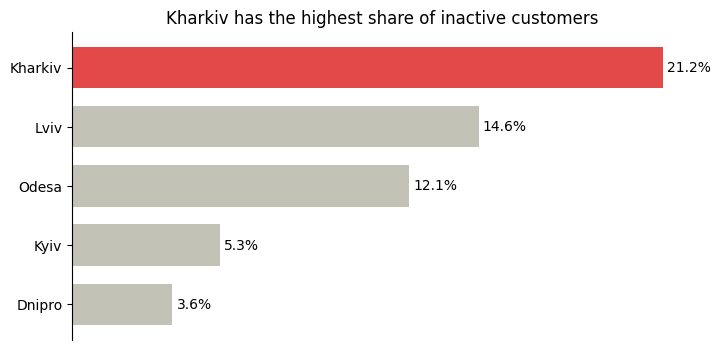

In [39]:
cust = customers.copy()
cust["is_inactive"] = ~cust["customer_id"].isin(orders["customer_id"])
inactive_share = (cust.groupby("city")["is_inactive"].mean() * 100).round(1).sort_values()

colors = ["#e34948" if city == inactive_share.idxmax() else "#c3c2b7" for city in inactive_share.index]

ax = inactive_share.plot(kind="barh", color=colors, width=0.7)
ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3)
ax.set_xticks([])
ax.grid(False)
ax.spines["bottom"].set_visible(False)
plt.title(f"{inactive_share.idxmax()} has the highest share of inactive customers")
plt.ylabel("")
plt.show()



---
# 📋 Шпаргалка блокнота 5

| Код | Що робить |
|---|---|
| `pd.merge(a, b, on="key", how="left")` | додати до `a` дані з `b` за ключем |
| `a.merge(b, on="key", how="left")` | те саме, інший запис |
| `how="inner"` / `"left"` / `"right"` / `"outer"` | які рядки лишаються |
| `left_on="x", right_on="y"` | ключі називаються по-різному |
| `validate="many_to_one"` | перевірити, що в довіднику немає дублікатів |
| `len(до) == len(після)` | ✅ перевірка після об'єднання |
| `~a["key"].isin(b["key"])` | рядки `a`, яких немає в `b` |
| `pd.concat([t1, t2], ignore_index=True)` | склеїти таблиці одна під одною |
| `display(table)` | показати таблицю посеред клітинки |
| `groupby(...).count().reset_index(name="n")` | результат групування → таблиця з назвою стовпця |

**📈 Графіки**

| Код | Що робить |
|---|---|
| `df[["a", "b"]].plot(kind="barh")` | два показники поруч |
| `df.columns = ["Name 1", "Name 2"]` | зрозумілі підписи в легенді |
| `df.plot(kind="scatter", x="a", y="b", s=60)` | точкова діаграма |
| `s=df["col"] / 2` | розмір точки залежить від числа (бульбашки) |
| `alpha=0.6` | напівпрозорість |
| `for name, row in df.iterrows(): plt.text(...)` | підписати точки |
| `edgecolor="white"` | білі проміжки між стовпчиками гістограми |
| `plt.legend(loc="lower right")` | місце легенди всередині графіка |

---
### ➡️ Далі: блокнот 6 «Робота з датами»
Динаміка по місяцях, дні тижня, час доставки, ковзне середнє. А 📈 у графіках динаміки навчимося підписувати місяці назвами, виділяти періоди, ставити стрілки-підписи і будувати «малі мультиплікатори».

In [ ]:
# @title 💡 Розв'язки практики: відкривайте, лише якщо справді застрягли
# Спершу спробуйте розв'язати кожне завдання самостійно в клітинках «Ваш код тут».

# ---------- Завдання 1 ----------
oc = orders.merge(customers, on="customer_id", how="left")
print("Rows before:", len(orders), "| after:", len(oc))

display(oc["city"].value_counts())

# ---------- Завдання 2 ----------
op = orders.merge(products, on="product_id", how="left")
op["profit"] = (op["price"] - op["cost"]) * op["quantity"]

op_delivered = op[op["status"] == "Delivered"]
display(op_delivered.groupby("product")["profit"].sum().sort_values(ascending=False).head(5))

# ---------- Завдання 3 ----------
full = (
    orders
    .merge(products, on="product_id", how="left")
    .merge(customers, on="customer_id", how="left")
)
display(full.groupby("category")["age"].mean().round(1).sort_values())
# Середній вік у всіх категоріях майже однаковий (32–33 роки): за віком покупці категорій не відрізняються.

# ---------- Завдання 4 ----------
cust = customers.copy()
cust["is_inactive"] = ~cust["customer_id"].isin(orders["customer_id"])

display((cust.groupby("city")["is_inactive"].mean() * 100).round(1).sort_values(ascending=False))
# Середнє від True/False — це частка True, тобто частка неактивних клієнтів.

# ---------- Завдання 5 ⭐ ----------
parts = []
for quarter in ["Q1", "Q2", "Q3", "Q4"]:
    part = pd.read_csv(f"sales_2025_{quarter}.csv")
    part["quarter"] = quarter
    parts.append(part)
year = pd.concat(parts, ignore_index=True)

year["revenue"] = year["price"] * year["quantity"]
by_quarter = year.groupby("quarter")["revenue"].sum() / 1000

by_quarter.plot(kind="bar", rot=0)       # rot=0 — підписи без нахилу
plt.title("Order value by quarter, thousand UAH")
plt.xlabel("")
plt.show()

display(by_quarter)

# ---------- Завдання 6 📈 ----------
op = orders.merge(products, on="product_id", how="left")
op["revenue"] = op["price"] * op["quantity"]
spend = op[op["status"] == "Delivered"].groupby("customer_id")["revenue"].sum().reset_index()
spend = spend.merge(customers, on="customer_id", how="left")

spend.plot(kind="scatter", x="age", y="revenue", alpha=0.5)
plt.title("Customer age and total spend for the year")
plt.xlabel("Age, years")
plt.ylabel("Total spend, UAH")
plt.show()
# Точки розкидані хаотично: зв'язку між віком і сумою покупок немає.
# «Зв'язку немає» — теж корисний висновок: таргетувати рекламу лише за віком сенсу мало.

# ---------- Завдання 7 📈⭐ ----------
cust = customers.copy()
cust["is_inactive"] = ~cust["customer_id"].isin(orders["customer_id"])
inactive_share = (cust.groupby("city")["is_inactive"].mean() * 100).round(1).sort_values()

colors = ["#e34948" if city == inactive_share.idxmax() else "#c3c2b7" for city in inactive_share.index]

ax = inactive_share.plot(kind="barh", color=colors, width=0.7)
ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3)
ax.set_xticks([])
ax.grid(False)
ax.spines["bottom"].set_visible(False)
plt.title(f"{inactive_share.idxmax()} has the highest share of inactive customers")
plt.ylabel("")
plt.show()
